In [1]:
# Check GPU availability
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA version: {torch.version.cuda}")

PyTorch version: 2.9.0+cu126
CUDA available: True
GPU: Tesla T4
CUDA version: 12.6


## 1. Install Dependencies & Download Dataset

In [2]:
# Install kaggle for dataset download
!pip install -q kaggle

# Create kaggle directory
!mkdir -p ~/.kaggle

In [13]:
# Upload your kaggle.json API key
# Get it from: https://www.kaggle.com/settings -> API -> Create New Token
from google.colab import files
print("Upload your kaggle.json file:")
uploaded = files.upload()

# Get the actual uploaded filename, which was 'kaggle (3) (2).json' in the previous run.
uploaded_filename = list(uploaded.keys())[0]

# Move to kaggle directory and rename it to kaggle.json for the API to recognize it
!mv "$uploaded_filename" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

Upload your kaggle.json file:


Saving kaggle (3).json to kaggle (3) (3).json


In [29]:
# Download Brain MRI Dataset
# Dataset: https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection
!kaggle datasets download -d navoneel/brain-mri-images-for-brain-tumor-detection
!unzip -q brain-mri-images-for-brain-tumor-detection.zip -d ./data
!rm brain-mri-images-for-brain-tumor-detection.zip

print("\nDataset downloaded!")
!ls -la ./data

Dataset URL: https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection
License(s): copyright-authors
  0% 0.00/15.1M [00:00<?, ?B/s]
100% 15.1M/15.1M [00:00<00:00, 1.47GB/s]
replace ./data/brain_tumor_dataset/no/1 no.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 
Dataset downloaded!
total 20
drwxr-xr-x 5 root root 4096 Dec  1 18:20 .
drwxr-xr-x 1 root root 4096 Dec  1 18:28 ..
drwxr-xr-x 4 root root 4096 Dec  1 18:20 brain_tumor_dataset
drwxr-xr-x 2 root root 4096 Dec  1 18:20 no
drwxr-xr-x 2 root root 4096 Dec  1 18:20 yes


In [5]:
# Alternative: If you don't have Kaggle API, download directly
# Uncomment and run this cell instead of the above

# import gdown
# import zipfile
# import os

# # Download from Google Drive (backup link)
# url = "https://drive.google.com/uc?id=1X4pzBXDQPKXVCvJ9ByxVJvPlhWV1sQVn"
# output = "brain_mri_data.zip"
# gdown.download(url, output, quiet=False)

# # Extract
# with zipfile.ZipFile(output, 'r') as zip_ref:
#     zip_ref.extractall('./data')
# os.remove(output)

## 2. Prepare Data Loaders

In [15]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import models, transforms
from tqdm import tqdm

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [16]:
# Configuration
CONFIG = {
    "input_size": (224, 224),
    "batch_size": 16,
    "epochs": 25,
    "learning_rate": 0.0001,
    "num_classes": 2,
    "train_split": 0.8,
}

# Data paths - adjust based on extracted structure
DATA_DIR = Path("./data")

# Check directory structure
print("Directory structure:")
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(str(DATA_DIR), '').count(os.sep)
    indent = ' ' * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 2:
        subindent = ' ' * 2 * (level + 1)
        for file in files[:3]:
            print(f"{subindent}{file}")
        if len(files) > 3:
            print(f"{subindent}... and {len(files)-3} more files")

Directory structure:
data/
  yes/
    Y159.JPG
    Y106.jpg
    Y15.jpg
    ... and 152 more files
  brain_tumor_dataset/
    yes/
    no/
  no/
    N5.jpg
    40 no.jpg
    43 no.jpg
    ... and 95 more files


In [17]:
class BrainMRIDataset(Dataset):
    """Dataset for Brain MRI images."""

    def __init__(self, data_dir, transform=None):
        self.data_dir = Path(data_dir)
        self.transform = transform
        self.samples = []
        self.class_names = []

        # Find the actual data directories
        # The dataset has 'yes' (tumor) and 'no' (no tumor) folders
        possible_structures = [
            {"no": 0, "yes": 1},  # Original structure
            {"no_tumor": 0, "tumor": 1},  # Alternative
            {"normal": 0, "tumor": 1},  # Another alternative
        ]

        # Try to find the correct structure
        for class_map in possible_structures:
            found = True
            for class_name in class_map.keys():
                if not (self.data_dir / class_name).exists():
                    # Check subdirectories
                    subdirs = [d for d in self.data_dir.iterdir() if d.is_dir()]
                    for subdir in subdirs:
                        if (subdir / class_name).exists():
                            self.data_dir = subdir
                            break
                    else:
                        found = False
                        break

            if found:
                self.class_to_idx = class_map
                break

        print(f"Data directory: {self.data_dir}")
        print(f"Class mapping: {self.class_to_idx}")

        # Load all image paths
        for class_name, class_idx in self.class_to_idx.items():
            class_dir = self.data_dir / class_name
            if class_dir.exists():
                for ext in ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']:
                    for img_path in class_dir.glob(ext):
                        self.samples.append((str(img_path), class_idx))
                print(f"  {class_name}: {len([s for s in self.samples if s[1] == class_idx])} images")

        print(f"Total samples: {len(self.samples)}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

In [18]:
# Data transforms
train_transform = transforms.Compose([
    transforms.Resize(CONFIG["input_size"]),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(CONFIG["input_size"]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create dataset
full_dataset = BrainMRIDataset(DATA_DIR, transform=train_transform)

# Split into train/val
train_size = int(CONFIG["train_split"] * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2)

print(f"\nTraining samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

Data directory: data
Class mapping: {'no': 0, 'yes': 1}
  no: 98 images
  yes: 155 images
Total samples: 253

Training samples: 202
Validation samples: 51


Sample images from training set:


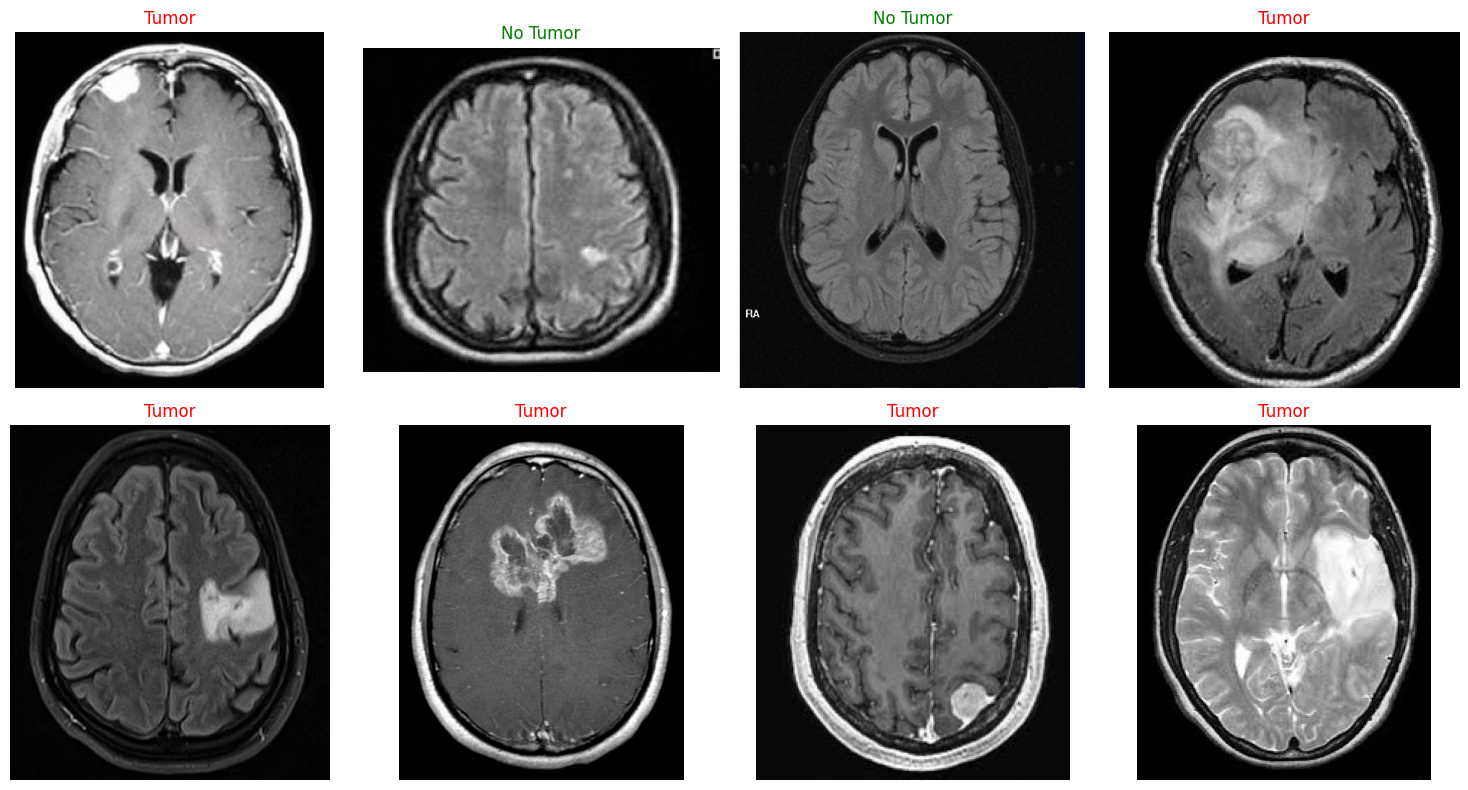

In [19]:
# Visualize some samples
def show_samples(dataset, n=8):
    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    class_names = ['No Tumor', 'Tumor']

    # Get original dataset for visualization
    original_dataset = dataset.dataset if hasattr(dataset, 'dataset') else dataset
    indices = dataset.indices if hasattr(dataset, 'indices') else range(len(dataset))

    for i, ax in enumerate(axes.flat):
        if i < len(indices):
            idx = indices[i]
            img_path, label = original_dataset.samples[idx]
            img = Image.open(img_path)
            ax.imshow(img, cmap='gray' if img.mode == 'L' else None)
            ax.set_title(f"{class_names[label]}", fontsize=12,
                        color='red' if label == 1 else 'green')
            ax.axis('off')

    plt.tight_layout()
    plt.show()

print("Sample images from training set:")
show_samples(train_dataset)

## 3. Build VGG16 Model

In [20]:
class BrainTumorCNN(nn.Module):
    """VGG16-based CNN for brain tumor detection."""

    def __init__(self, num_classes=2, pretrained=True):
        super(BrainTumorCNN, self).__init__()

        # Load pretrained VGG16
        self.vgg16 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None)

        # Freeze early layers
        for param in self.vgg16.features[:20].parameters():
            param.requires_grad = False

        # Replace classifier
        num_features = self.vgg16.classifier[0].in_features
        self.vgg16.classifier = nn.Sequential(
            nn.Linear(num_features, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(1024, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

        # Feature extractor for RAG integration (512-dim embedding)
        self.feature_extractor = nn.Sequential(
            self.vgg16.features,
            self.vgg16.avgpool,
            nn.Flatten(),
            nn.Linear(512 * 7 * 7, 512)
        )

    def forward(self, x):
        return self.vgg16(x)

    def extract_features(self, x):
        return self.feature_extractor(x)

# Create model
model = BrainTumorCNN(num_classes=CONFIG["num_classes"]).to(device)

# Print model summary
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 79.0MB/s]


Total parameters: 134,783,042
Trainable parameters: 129,507,586


## 4. Train the Model

In [21]:
# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

# Training history
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

In [22]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(loader, desc="Training")
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        pbar.set_postfix({'loss': f'{running_loss/total:.4f}', 'acc': f'{100.*correct/total:.2f}%'})

    return running_loss / total, 100. * correct / total


def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

In [23]:
# Training loop
best_val_acc = 0.0
best_model_state = None

print("="*60)
print("Starting Training")
print("="*60)

for epoch in range(CONFIG["epochs"]):
    print(f"\nEpoch {epoch+1}/{CONFIG['epochs']}")
    print("-" * 40)

    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)

    # Validate
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    # Update scheduler
    scheduler.step(val_loss)

    # Save history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = model.state_dict().copy()
        print(f"✓ New best model! Val Acc: {val_acc:.2f}%")

print("\n" + "="*60)
print(f"Training Complete! Best Val Accuracy: {best_val_acc:.2f}%")
print("="*60)

Starting Training

Epoch 1/25
----------------------------------------


Training: 100%|██████████| 13/13 [00:04<00:00,  3.11it/s, loss=0.6486, acc=59.41%]


Train Loss: 0.6486 | Train Acc: 59.41%
Val Loss: 0.6164 | Val Acc: 76.47%
✓ New best model! Val Acc: 76.47%

Epoch 2/25
----------------------------------------


Training: 100%|██████████| 13/13 [00:02<00:00,  5.19it/s, loss=0.4367, acc=82.18%]


Train Loss: 0.4367 | Train Acc: 82.18%
Val Loss: 0.6504 | Val Acc: 76.47%

Epoch 3/25
----------------------------------------


Training: 100%|██████████| 13/13 [00:01<00:00,  6.61it/s, loss=0.2523, acc=91.58%]


... (41 outputs left out)

Training: 100%|██████████| 13/13 [00:02<00:00,  6.41it/s, loss=0.0299, acc=99.50%]


Train Loss: 0.0299 | Train Acc: 99.50%
Val Loss: 1.7402 | Val Acc: 80.39%

Epoch 25/25
----------------------------------------


Training: 100%|██████████| 13/13 [00:02<00:00,  6.49it/s, loss=0.0187, acc=99.50%]


Train Loss: 0.0187 | Train Acc: 99.50%
Val Loss: 2.1367 | Val Acc: 70.59%

Training Complete! Best Val Accuracy: 86.27%


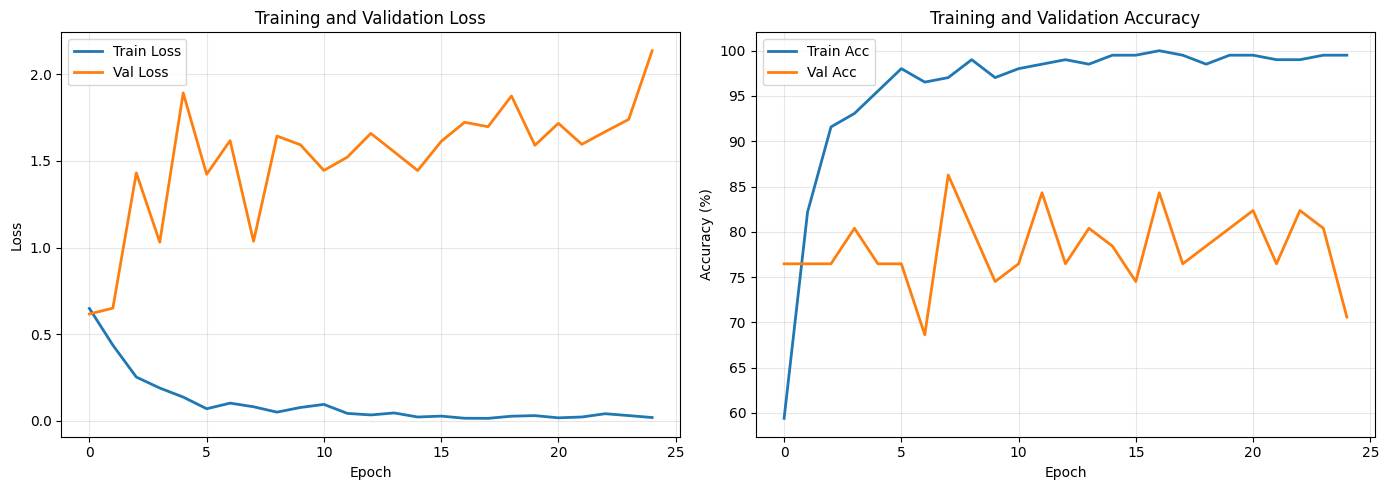

In [24]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax1.plot(history["train_loss"], label="Train Loss", linewidth=2)
ax1.plot(history["val_loss"], label="Val Loss", linewidth=2)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Training and Validation Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Accuracy
ax2.plot(history["train_acc"], label="Train Acc", linewidth=2)
ax2.plot(history["val_acc"], label="Val Acc", linewidth=2)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Training and Validation Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_history.png", dpi=150)
plt.show()

## 5. Evaluate Model

Classification Report:
              precision    recall  f1-score   support

    No Tumor       0.65      0.65      0.65        17
       Tumor       0.82      0.82      0.82        34

    accuracy                           0.76        51
   macro avg       0.74      0.74      0.74        51
weighted avg       0.76      0.76      0.76        51



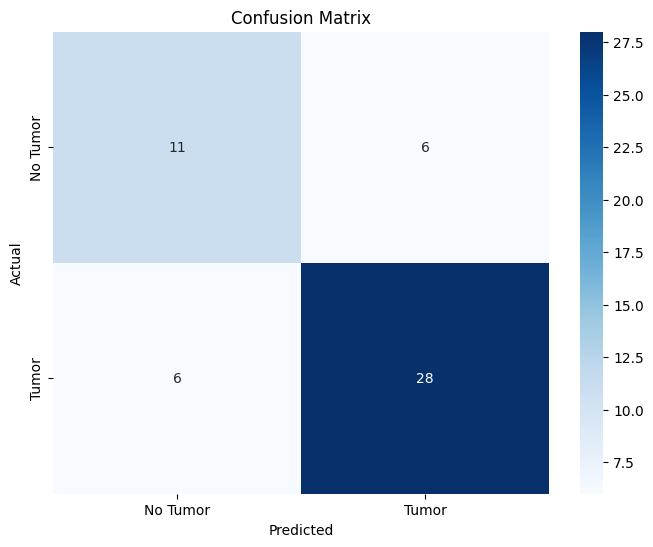

In [25]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Load best model
model.load_state_dict(best_model_state)
model.eval()

# Get predictions
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Classification report
class_names = ['No Tumor', 'Tumor']
print("Classification Report:")
print("="*50)
print(classification_report(all_labels, all_preds, target_names=class_names))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

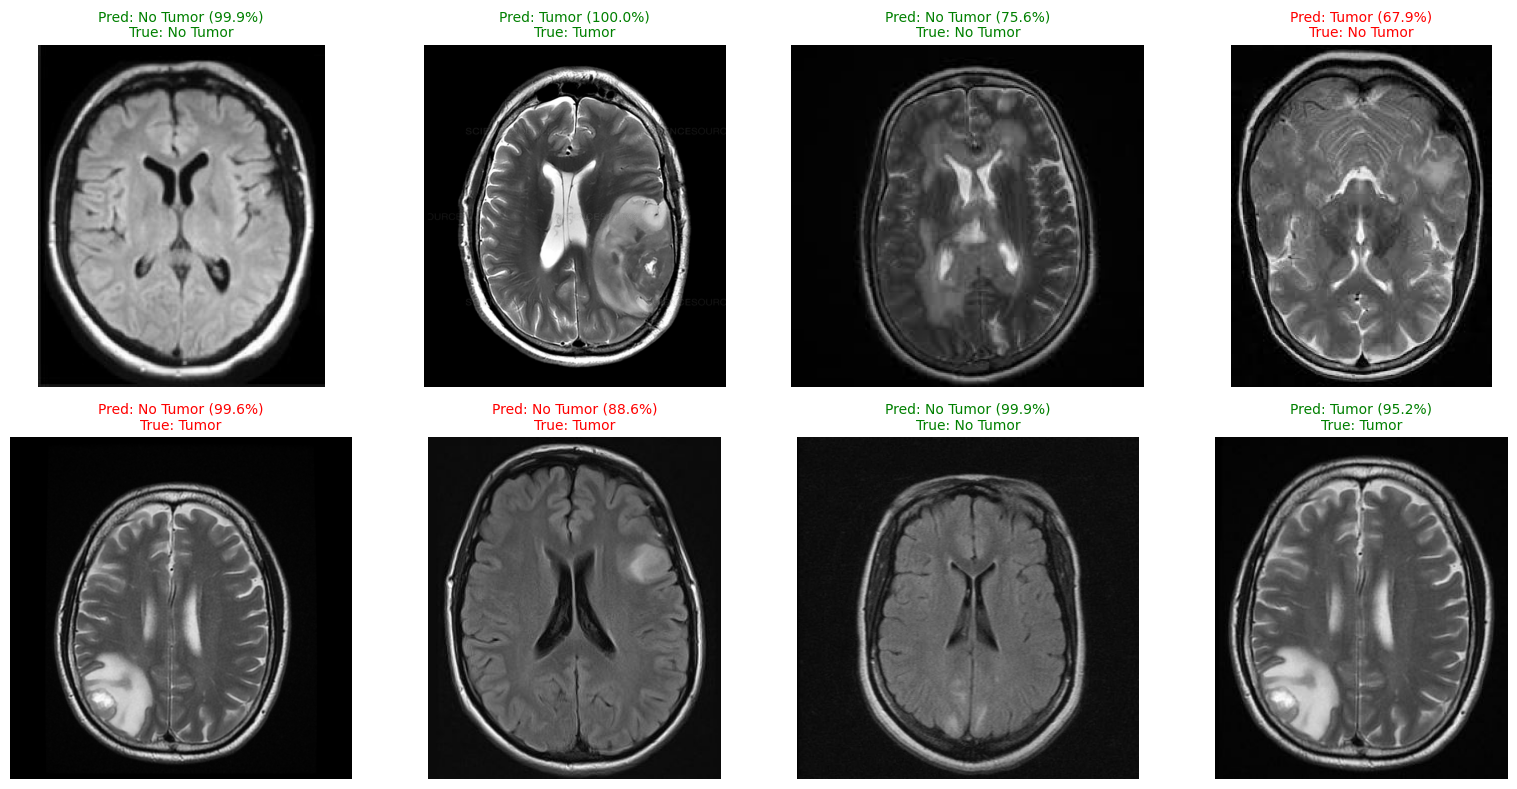

In [26]:
# Test on some sample images
def predict_and_show(model, dataset, n=8):
    model.eval()
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    class_names = ['No Tumor', 'Tumor']

    original_dataset = dataset.dataset if hasattr(dataset, 'dataset') else dataset
    indices = dataset.indices if hasattr(dataset, 'indices') else range(len(dataset))

    # Random sample
    sample_indices = np.random.choice(len(indices), min(n, len(indices)), replace=False)

    for i, ax in enumerate(axes.flat):
        if i < len(sample_indices):
            idx = indices[sample_indices[i]]
            img_path, true_label = original_dataset.samples[idx]

            # Load and predict
            img = Image.open(img_path).convert('RGB')
            img_tensor = val_transform(img).unsqueeze(0).to(device)

            with torch.no_grad():
                output = model(img_tensor)
                probs = torch.softmax(output, dim=1)
                pred = output.argmax(1).item()
                conf = probs[0][pred].item()

            # Display
            ax.imshow(img)
            color = 'green' if pred == true_label else 'red'
            ax.set_title(f"Pred: {class_names[pred]} ({conf*100:.1f}%)\nTrue: {class_names[true_label]}",
                        color=color, fontsize=10)
            ax.axis('off')

    plt.tight_layout()
    plt.savefig("predictions.png", dpi=150)
    plt.show()

predict_and_show(model, val_dataset)

## 6. Save Model for RAG-CNN System

In [27]:
# Save model in the format expected by RAG-CNN system
save_path = "brain_tumor_cnn.pth"

# Save only the VGG16 state dict (compatible with our system)
torch.save(model.vgg16.state_dict(), save_path)
print(f"Model saved to {save_path}")

# Also save full model for backup
torch.save({
    'model_state_dict': model.state_dict(),
    'vgg16_state_dict': model.vgg16.state_dict(),
    'config': CONFIG,
    'best_val_acc': best_val_acc,
    'history': history,
    'class_names': ['No Tumor', 'Tumor']
}, "brain_tumor_cnn_full.pth")
print("Full model checkpoint saved to brain_tumor_cnn_full.pth")

Model saved to brain_tumor_cnn.pth
Full model checkpoint saved to brain_tumor_cnn_full.pth


In [28]:
# Download the trained model
from google.colab import files

print("Downloading trained model...")
files.download('brain_tumor_cnn.pth')
files.download('brain_tumor_cnn_full.pth')
files.download('training_history.png')
files.download('confusion_matrix.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Instructions for Using the Model

After downloading the model:

1. **Copy `brain_tumor_cnn.pth`** to your RAG-CNN project's `models/` folder

2. **Update your local project** to load the trained model:
   ```python
   from cnn_model import BrainTumorCNN
   
   model = BrainTumorCNN(model_path="models/brain_tumor_cnn.pth")
   result = model.predict("path/to/mri_image.jpg")
   print(result)
   ```

3. **Run your Streamlit app**:
   ```bash
   streamlit run app.py
   ```

The model should now correctly classify brain MRI images!

In [30]:
# Test inference function (for verification)
def test_inference(model, image_path):
    """Test inference on a single image."""
    model.eval()

    # Load and preprocess
    img = Image.open(image_path).convert('RGB')
    img_tensor = val_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img_tensor)
        probs = torch.softmax(output, dim=1)
        pred_class = output.argmax(1).item()
        confidence = probs[0][pred_class].item()

        # Get feature embedding
        features = model.extract_features(img_tensor)

    class_names = ['No Tumor', 'Tumor']

    return {
        'prediction': class_names[pred_class],
        'confidence': f"{confidence*100:.2f}%",
        'tumor_probability': f"{probs[0][1].item()*100:.2f}%",
        'normal_probability': f"{probs[0][0].item()*100:.2f}%",
        'embedding_shape': features.shape
    }

# Test on a sample image
sample_img = full_dataset.samples[0][0]
result = test_inference(model, sample_img)
print("\nSample Inference Result:")
for k, v in result.items():
    print(f"  {k}: {v}")


Sample Inference Result:
  prediction: No Tumor
  confidence: 99.51%
  tumor_probability: 0.49%
  normal_probability: 99.51%
  embedding_shape: torch.Size([1, 512])


---
## ✅ Training Complete!

Download the `brain_tumor_cnn.pth` file and place it in your project's `models/` folder.

The model will automatically be loaded when you run the Streamlit app.